# 365 Automobiles — Sales and Service Analysis


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

DATA = Path("data")
sales = pd.read_csv(DATA / "365_Automobiles_Sales.csv")
service = pd.read_csv(DATA / "365_Automobiles_Service.csv")
sales["enquiry_date"] = pd.to_datetime(sales["enquiry_date"], errors="coerce")
service["service_date"] = pd.to_datetime(service["service_date"], errors="coerce")

for name, df, date_col in [("Sales", sales, "enquiry_date"), ("Service", service, "service_date")]:
    print(f"\n{name}: {len(df):,} rows x {df.shape[1]} columns")
    print("Date coverage:", df[date_col].min(), "to", df[date_col].max())
    print("Duplicate rows:", df.duplicated().sum())
    display(df.isna().sum().sort_values(ascending=False).head(12).to_frame("missing_count"))


Sales: 12,000 rows x 39 columns
Date coverage: 2024-01-01 00:00:00 to 2025-07-01 00:00:00
Duplicate rows: 0


,missing_count
vehicle_id,8426
days_to_delivery,8426
final_price_aed,8426
lead_source,0
lead_id,0
enquiry_date,0
showroom_location,0
emirate,0
customer_gender,0
customer_age,0



Service: 9,178 rows x 18 columns
Date coverage: 2024-04-09 00:00:00 to 2025-12-19 00:00:00
Duplicate rows: 0


,missing_count
service_id,0
vehicle_id,0
model,0
trim,0
service_centre,0
service_date,0
vehicle_age_months,0
odometer_km,0
visit_number,0
service_type,0


## 1. Explore the business data
The sales table contains both buyers and non-buyers. Blank price and vehicle identifiers for non-buyers are expected. Service rows are workshop visits, so a vehicle may appear more than once.

Purchase status:


,leads
purchased,
No,8426
Yes,3574


Conversions by interested model:


purchased,No,Yes
model_interested,,
Aura Premium,0.677,0.323
Terra SUV,0.717,0.283
Volt City,0.687,0.313
Volt Sedan,0.725,0.275


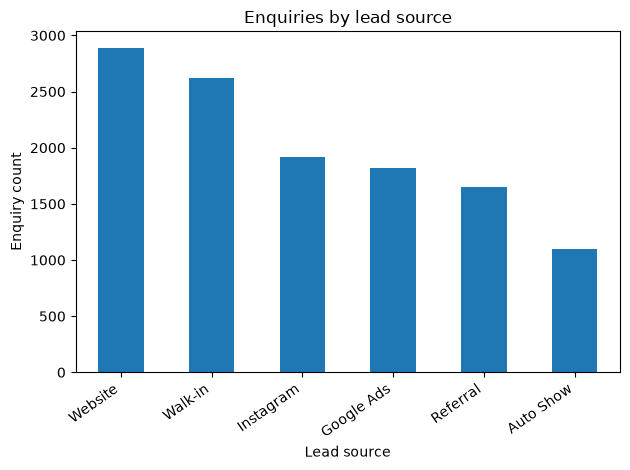

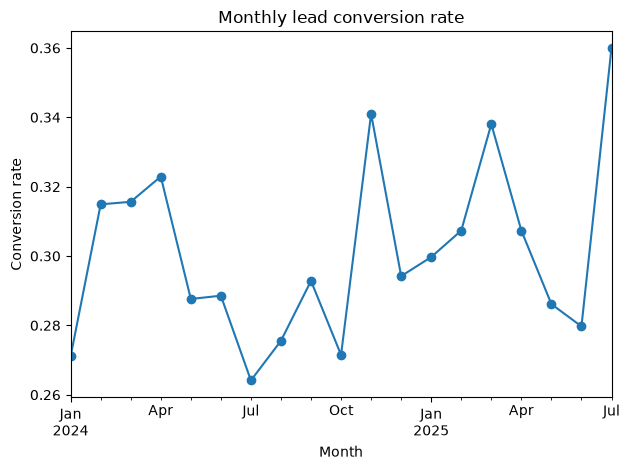

Service cost by model:


,count,mean,median
model,,,
Aura Premium,1264,2497.33,2415.0
Terra SUV,1585,1843.98,1760.0
Volt City,3813,1320.28,1260.0
Volt Sedan,2516,1582.86,1540.0


Service centre experience:


,avg_wait_days,avg_satisfaction,repeat_rate,visits
service_centre,,,,
Abu Dhabi - Mussafah,2.94,4.64,0.17,2805
Dubai - Al Quoz,2.97,4.62,0.18,4358
Sharjah - Industrial Area,3.00,4.62,0.16,2015


In [3]:
print("Purchase status:")
display(sales["purchased"].value_counts(dropna=False).to_frame("leads"))
print("Conversions by interested model:")
display(pd.crosstab(sales["model_interested"], sales["purchased"], normalize="index").round(3))

fig, ax = plt.subplots()
sales["lead_source"].value_counts().plot(kind="bar", ax=ax)
ax.set_title("Enquiries by lead source"); ax.set_xlabel("Lead source"); ax.set_ylabel("Enquiry count")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots()
sales.groupby(sales["enquiry_date"].dt.to_period("M"))["purchased"].apply(lambda x: (x=="Yes").mean()).plot(marker="o", ax=ax)
ax.set_title("Monthly lead conversion rate"); ax.set_xlabel("Month"); ax.set_ylabel("Conversion rate")
plt.tight_layout(); plt.show()

print("Service cost by model:")
display(service.groupby("model")["service_cost_aed"].agg(["count", "mean", "median"]).round(2))
print("Service centre experience:")
display(service.groupby("service_centre").agg(avg_wait_days=("workshop_wait_days","mean"),
    avg_satisfaction=("customer_satisfaction","mean"), repeat_rate=("repeat_visit_30_days",lambda x:(x=="Yes").mean()),
    visits=("service_id","count")).round(2))

## 2. Model A — Estimate final selling price


R-squared: 0.921
MAE (AED): 8692.81
RMSE (AED): 16876.01


,actual_AED,predicted_AED
6068,173700.0,180059.77
9157,205700.0,207647.52
117,126410.0,130699.57
1720,236110.0,223379.21
10613,265900.0,260095.46
11746,89830.0,91937.59
8356,222070.0,224309.51
1666,261300.0,257061.13
6823,152760.0,148787.00
8874,156230.0,155515.81


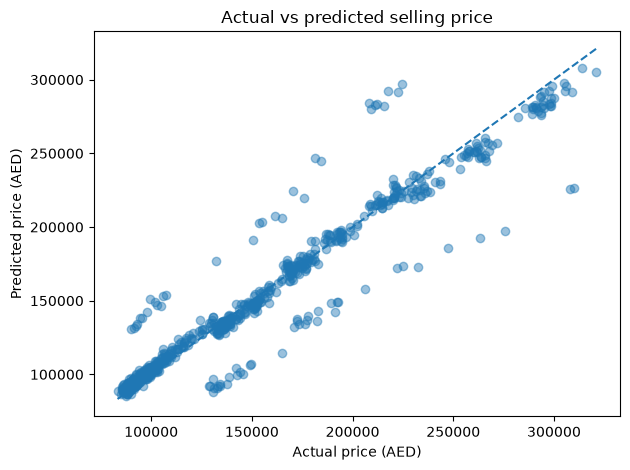

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
    confusion_matrix, classification_report, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score)

buyers = sales.loc[sales["purchased"].astype(str).str.strip().str.lower().eq("yes")].copy()
price_target = "final_price_aed"
price_num = ["list_price_aed", "options_value_aed", "customer_age", "monthly_income_aed",
             "years_at_current_job", "showroom_visits", "days_in_pipeline",
             "tradein_value_aed", "salesperson_experience_yrs"]
price_cat = ["showroom_location", "lead_source", "customer_gender", "emirate",
            "employment_type", "existing_customer", "model_interested", "trim_interested",
            "segment", "exterior_colour", "has_tradein"]
price_features = price_num + price_cat
price_df = buyers[price_features + [price_target]].copy()
price_df = price_df.dropna(subset=[price_target])
X_price, y_price = price_df[price_features], price_df[price_target]
X_train, X_test, y_train, y_test = train_test_split(X_price, y_price, test_size=0.2, random_state=42)
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
price_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
price_model = Pipeline([("prep", price_prep), ("regression", LinearRegression())])
price_model.fit(X_train, y_train)
price_pred = price_model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, price_pred))
print("R-squared:", round(r2_score(y_test, price_pred), 3))
print("MAE (AED):", round(mean_absolute_error(y_test, price_pred), 2))
print("RMSE (AED):", round(rmse, 2))
price_compare = pd.DataFrame({"actual_AED": y_test, "predicted_AED": price_pred})
display(price_compare.head(12).round(2))

fig, ax = plt.subplots()
ax.scatter(y_test, price_pred, alpha=0.45)
low, high = min(y_test.min(), price_pred.min()), max(y_test.max(), price_pred.max())
ax.plot([low, high], [low, high], linestyle="--")
ax.set_title("Actual vs predicted selling price"); ax.set_xlabel("Actual price (AED)"); ax.set_ylabel("Predicted price (AED)")
plt.tight_layout(); plt.show()

### Price-model interpretation prompt
The model has an MAE of AED 8,693.39 and an RMSE of AED 16,875.54, which means its predictions can differ noticeably from actual prices. The graph also shows that some higher-priced vehicles are underestimated. Battery capacity, driving range, and motor power are related EV specifications, so I excluded them together to avoid redundant information in this simpler model.

## 3. Model B — Lead conversion
Predict purchase status for every enquiry. Only use information available early in the sales process. Late-stage finance and negotiation fields are intentionally excluded.

In [5]:
lead_num = ["customer_age", "monthly_income_aed", "years_at_current_job", "showroom_visits",
            "days_in_pipeline", "tradein_value_aed", "salesperson_experience_yrs"]
lead_cat = ["showroom_location", "lead_source", "customer_gender", "emirate", "employment_type",
            "existing_customer", "model_interested", "trim_interested", "segment", "exterior_colour",
            "test_drive_taken", "brochure_downloaded", "finance_quote_requested", "has_tradein"]
lead_features = lead_num + lead_cat
lead_df = sales[lead_features + ["purchased"]].copy()
lead_df = lead_df.dropna(subset=["purchased"])
y_lead = lead_df["purchased"].astype(str).str.strip().str.lower().map({"no":0,"yes":1})
valid = y_lead.notna(); lead_df, y_lead = lead_df.loc[valid], y_lead.loc[valid].astype(int)
X_lead = lead_df[lead_features]
X_train, X_test, y_train, y_test = train_test_split(X_lead, y_lead, test_size=0.2, random_state=42, stratify=y_lead)
num_cols = X_train.select_dtypes(include=np.number).columns.tolist(); cat_cols = [c for c in X_train.columns if c not in num_cols]
lead_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
lead_model = Pipeline([("prep", lead_prep), ("classifier", RandomForestClassifier(n_estimators=150, random_state=42, class_weight="balanced", min_samples_leaf=3, n_jobs=-1))])
lead_model.fit(X_train, y_train)
lead_pred = lead_model.predict(X_test); lead_prob = lead_model.predict_proba(X_test)[:,1]
print("Confusion matrix:\n", confusion_matrix(y_test, lead_pred))
print(classification_report(y_test, lead_pred, target_names=["Not purchased", "Purchased"], zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, lead_prob), 4))
print("Majority-class baseline accuracy:", round(y_test.value_counts(normalize=True).max(), 4))

Confusion matrix:
 [[1315  370]
 [ 251  464]]
               precision    recall  f1-score   support

Not purchased       0.84      0.78      0.81      1685
    Purchased       0.56      0.65      0.60       715

     accuracy                           0.74      2400
    macro avg       0.70      0.71      0.70      2400
 weighted avg       0.76      0.74      0.75      2400

ROC-AUC: 0.7938
Majority-class baseline accuracy: 0.7021


## 4. Model C — Which model will a converted buyer purchase?
Train only on buyers. The input `model_interested` is allowed because it is known at enquiry time. The target is the actual purchased model. Do not include post-sale or late-stage finance/negotiation fields.

In [6]:
model_target = "model_purchased"
model_num = ["customer_age", "monthly_income_aed", "years_at_current_job", "showroom_visits",
             "days_in_pipeline", "salesperson_experience_yrs"]
model_cat = ["showroom_location", "lead_source", "customer_gender", "emirate", "employment_type",
             "existing_customer", "model_interested", "trim_interested", "segment", "exterior_colour",
             "test_drive_taken", "brochure_downloaded", "finance_quote_requested", "has_tradein"]
model_features = model_num + model_cat
model_df = buyers[model_features + [model_target]].dropna(subset=[model_target]).copy()
X_model, y_model = model_df[model_features], model_df[model_target].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X_model, y_model, test_size=0.2, random_state=42, stratify=y_model)
num_cols = X_train.select_dtypes(include=np.number).columns.tolist(); cat_cols = [c for c in X_train.columns if c not in num_cols]
model_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
vehicle_model = Pipeline([("prep", model_prep), ("classifier", RandomForestClassifier(n_estimators=150, random_state=42, class_weight="balanced", min_samples_leaf=2, n_jobs=-1))])
vehicle_model.fit(X_train, y_train)
vehicle_pred = vehicle_model.predict(X_test)
print("Confusion matrix (class order shown below):")
print(list(vehicle_model.named_steps["classifier"].classes_))
print(confusion_matrix(y_test, vehicle_pred, labels=vehicle_model.named_steps["classifier"].classes_))
print(classification_report(y_test, vehicle_pred, zero_division=0))
print("Accuracy:", round(accuracy_score(y_test, vehicle_pred), 4))

Confusion matrix (class order shown below):
['Aura Premium', 'Terra SUV', 'Volt City', 'Volt Sedan']
[[ 87  10   0   0]
 [ 14 102   0   8]
 [  0   0 280  19]
 [  0   6  20 169]]
              precision    recall  f1-score   support

Aura Premium       0.86      0.90      0.88        97
   Terra SUV       0.86      0.82      0.84       124
   Volt City       0.93      0.94      0.93       299
  Volt Sedan       0.86      0.87      0.86       195

    accuracy                           0.89       715
   macro avg       0.88      0.88      0.88       715
weighted avg       0.89      0.89      0.89       715

Accuracy: 0.8923


## 5. Service-side analysis
Compare service cost, battery health, waiting time and repeat visits. For the sales-to-service join, use one row per service visit and avoid summing repeated sales values across multiple service rows.

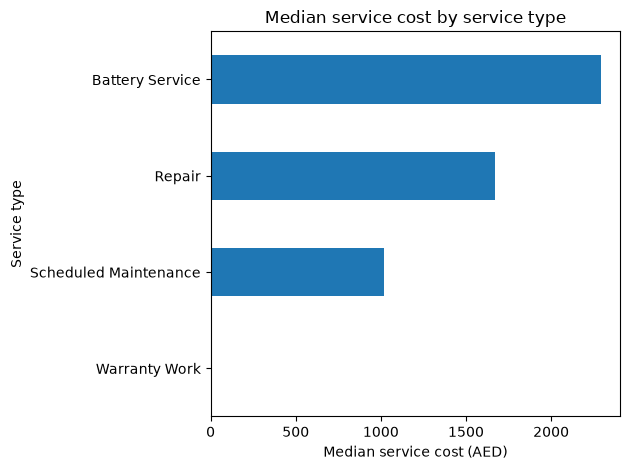

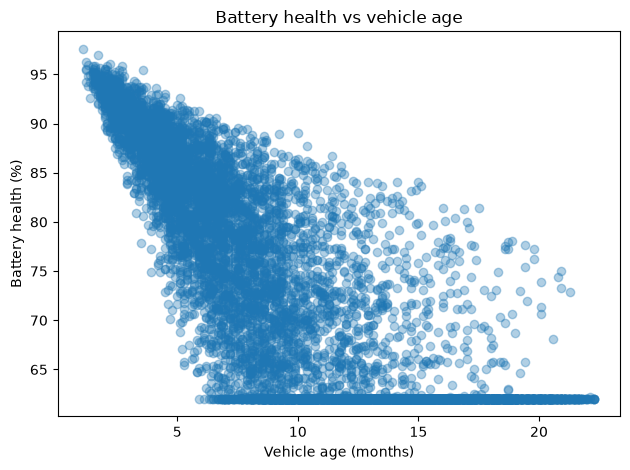

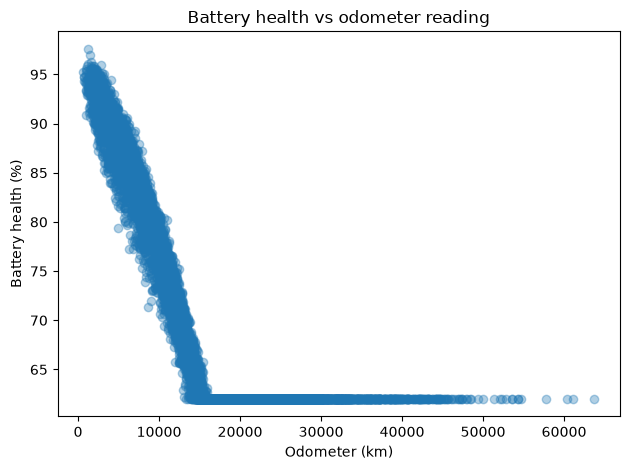

Repeat visit rate by service centre:


,repeat_rate,visits,avg_wait_days,avg_satisfaction
service_centre,,,,
Abu Dhabi - Mussafah,0.169,2805,2.941,4.639
Dubai - Al Quoz,0.179,4358,2.969,4.618
Sharjah - Industrial Area,0.161,2015,2.999,4.621


Vehicles with sales and service history: 3265


,vehicles,avg_service_cost,avg_visits,avg_battery_health
model_purchased,,,,
Aura Premium,444,2428.25,2.85,74.62
Terra SUV,570,1819.75,2.78,74.50
Volt City,1369,1292.48,2.79,73.42
Volt Sedan,882,1540.47,2.85,73.94


In [ ]:
fig, ax = plt.subplots()
service.groupby("service_type")["service_cost_aed"].median().sort_values().plot(kind="barh", ax=ax)
ax.set_title("Median service cost by service type"); ax.set_xlabel("Median service cost (AED)"); ax.set_ylabel("Service type")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots()
ax.scatter(service["vehicle_age_months"], service["battery_health_pct"], alpha=0.35)
ax.set_title("Battery health vs vehicle age"); ax.set_xlabel("Vehicle age (months)"); ax.set_ylabel("Battery health (%)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots()
ax.scatter(service["odometer_km"], service["battery_health_pct"], alpha=0.35)
ax.set_title("Battery health vs odometer reading"); ax.set_xlabel("Odometer (km)"); ax.set_ylabel("Battery health (%)")
plt.tight_layout(); plt.show()

print("Repeat visit rate by service centre:")
display(service.assign(repeat_flag=service["repeat_visit_30_days"].astype(str).str.lower().eq("yes"))
        .groupby("service_centre").agg(repeat_rate=("repeat_flag","mean"), visits=("service_id","count"),
        avg_wait_days=("workshop_wait_days","mean"), avg_satisfaction=("customer_satisfaction","mean")).round(3))

# Join at service visit grain Sales fields repeat for vehicles with multiple service visits so summarizing service data by vehicle first
service_by_vehicle = service.groupby("vehicle_id", as_index=False).agg(
    service_visits=("service_id","count"), avg_service_cost=("service_cost_aed","mean"),
    avg_battery_health=("battery_health_pct","mean"), avg_wait_days=("workshop_wait_days","mean"))
vehicle_sales = buyers[["vehicle_id", "model_purchased", "segment", "final_price_aed"]].drop_duplicates("vehicle_id")
joined = vehicle_sales.merge(service_by_vehicle, on="vehicle_id", how="inner")
print("Vehicles with sales and service history:", len(joined))
display(joined.groupby("model_purchased").agg(vehicles=("vehicle_id","count"), avg_service_cost=("avg_service_cost","mean"),
    avg_visits=("service_visits","mean"), avg_battery_health=("avg_battery_health","mean")).round(2))

## 6. Final business conclusions

1. Sales: Out of 12,000 enquiries, 3,574 resulted in purchases (29.8%). Since purchaser recall is 54%, sales staff should also follow up with customers missed by the model.
2. Pricing: The MAE is AED 8,693.39 and RMSE is AED 16,875.54. Price predictions should be treated as estimates, not exact values.
3. Stock Planning: The vehicle-model prediction accuracy is 89.23%. The company can use this as supporting information alongside actual sales and customer demand.
4. After-Sales Service: Dubai – Al Quoz has the highest repeat-visit rate (17.9%). The company should review service records to understand possible reasons for repeat visits.